In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import warnings
import mahotas
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C5"
DTYPE="CMMS"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C5_10,28,"[DATA/TRAINING/C5/C5_10/IMG_7706.HEIC, DATA/TR..."
1,C5_11,30,"[DATA/TRAINING/C5/C5_11/IMG_7780.HEIC, DATA/TR..."
2,C5_12,26,"[DATA/TRAINING/C5/C5_12/IMG_7858.HEIC, DATA/TR..."
3,C5_13,27,"[DATA/TRAINING/C5/C5_13/IMG_7917.HEIC, DATA/TR..."
4,C5_14,27,"[DATA/TRAINING/C5/C5_14/IMG_7981.HEIC, DATA/TR..."
5,C5_15,28,"[DATA/TRAINING/C5/C5_15/IMG_8046.jpg, DATA/TRA..."
6,C5_16,25,"[DATA/TRAINING/C5/C5_16/IMG_8109.HEIC, DATA/TR..."


In [3]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [4]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [5]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

In [6]:
def read_image(pic_path):
    ext = pic_path.split(".")[1]
    if ext=="HEIC":
        return read_imgHEIC(pic_path)
    else:
        img=cv2.imread(pic_path)
        return img

Text(0.5, 1.0, '16% IMG_8144.HEIC')

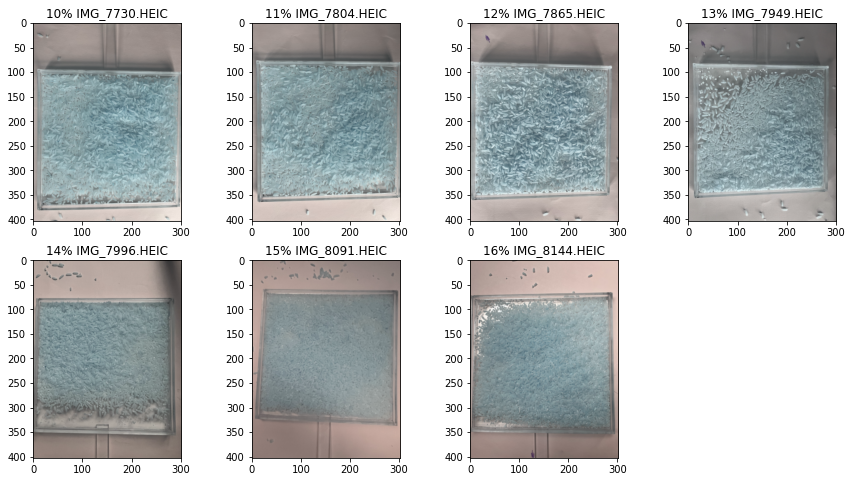

In [7]:
fig=plt.figure(figsize=(15, 8)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_image(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_image(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_image(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_image(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_image(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_image(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_image(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [8]:
def color_moments(image):
    # Split the channels - h,s,v
    h, s, v = cv2.split(image)
    # Initialize the color feature
    color_feature = []
    # N = h.shape[0] * h.shape[1]
    
    # The first central moment - average
    h_mean = np.mean(h)  # np.sum(h)/float(N)
    s_mean = np.mean(s)  # np.sum(s)/float(N)
    v_mean = np.mean(v)  # np.sum(v)/float(N)
    color_feature.extend([h_mean, s_mean, v_mean])
    
    # The second central moment - standard deviation
    h_std = np.std(h)  # np.sqrt(np.mean(abs(h - h.mean())**2))
    s_std = np.std(s)  # np.sqrt(np.mean(abs(s - s.mean())**2))
    v_std = np.std(v)  # np.sqrt(np.mean(abs(v - v.mean())**2))
    color_feature.extend([h_std, s_std, v_std])
    
    # The third central moment - the third root of the skewness
    h_skewness = np.mean(abs(h - h.mean())**3)
    s_skewness = np.mean(abs(s - s.mean())**3)
    v_skewness = np.mean(abs(v - v.mean())**3)
    h_thirdMoment = h_skewness**(1./3)
    s_thirdMoment = s_skewness**(1./3)
    v_thirdMoment = v_skewness**(1./3)
    color_feature.extend([h_thirdMoment, s_thirdMoment, v_thirdMoment])
    """
    # The second central moment - standard deviation
    hist_h = cv2.calcHist([h], [0], None, [256], [0, 256])
    hist_h = cv2.normalize(hist_h, hist_h, 0, 1, cv2.NORM_MINMAX)

    hist_s = cv2.calcHist([s], [0], None, [256], [0, 256])
    hist_s = cv2.normalize(hist_s, hist_s, 0, 1, cv2.NORM_MINMAX)

    hist_v = cv2.calcHist([v], [0], None, [256], [0, 256])
    hist_v = cv2.normalize(hist_v, hist_v, 0, 1, cv2.NORM_MINMAX)

    h_skew = kurtosis(hist_h)  
    s_skew = kurtosis(hist_s) 
    v_skew = kurtosis(hist_v) 
    color_feature.extend([h_skew[0], s_skew[0], v_skew[0]])
    
    
    h_kts = kurtosis(hist_h)  
    s_kts = kurtosis(hist_s) 
    v_kts = kurtosis(hist_v) 
    color_feature.extend([h_kts[0], s_kts[0], v_kts[0]])
    
    # The second central moment - standard deviation
    h_ent = entropy(hist_h)  
    s_ent = entropy(hist_s) 
    v_ent = entropy(hist_v) 
    color_feature.extend([h_ent, s_ent, v_ent])
    """
    return color_feature

In [154]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=3
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

        features = color_moments(hsv)
        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [155]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,scale,height,width,channels,IMAGENAME,HUMIDITY
0,53.601019,34.247315,161.734352,39.374025,20.061674,29.401765,42.110004,22.282370,34.439099,3,120,90,3,IMG_7706.HEIC,10
1,54.341389,33.579815,160.668519,40.115489,17.713254,30.621351,42.727630,19.916424,35.963179,3,120,90,3,IMG_7709.HEIC,10
2,52.470556,39.944630,160.659259,39.778973,22.420598,29.712661,42.603069,24.690634,35.063689,3,120,90,3,IMG_7710.HEIC,10
3,52.786944,40.548148,164.755000,39.297786,21.560232,27.126623,41.950012,23.672245,32.714943,3,120,90,3,IMG_7713.HEIC,10
4,53.125000,40.105833,164.549444,39.156601,22.296421,26.009268,41.696886,24.471518,31.407042,3,120,90,3,IMG_7714.HEIC,10
5,51.786389,39.147222,163.385741,38.785202,20.631085,23.430036,41.839972,22.321748,29.320271,3,120,90,3,IMG_7718.HEIC,10
6,51.884259,42.555926,163.581574,38.568805,22.691278,27.179963,41.402340,25.764042,33.401955,3,120,90,3,IMG_7719.HEIC,10
7,54.376389,38.089815,164.746759,40.274021,17.403956,26.233507,42.553171,19.788333,31.889683,3,120,90,3,IMG_7721.HEIC,10
8,54.013241,38.370648,159.822685,38.685842,18.049216,24.975676,41.078544,20.012541,31.163934,3,120,90,3,IMG_7723.HEIC,10
9,54.631204,32.846111,160.942315,40.730415,15.507102,23.100102,43.134439,17.916467,29.514492,3,120,90,3,IMG_7725.HEIC,10


# Classification

In [156]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-6]
#X

In [157]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [158]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [159]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [160]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [161]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.750000,0.785714,0.761905,0.773626,CMMS,C5,RF_C,3,120,90,3
1,2,0.947368,0.964286,0.952381,0.958296,CMMS,C5,RF_C,3,120,90,3
2,3,0.789474,0.750000,0.809524,0.778626,CMMS,C5,RF_C,3,120,90,3
3,4,0.789474,0.821429,0.809524,0.815433,CMMS,C5,RF_C,3,120,90,3
4,5,0.842105,0.857143,0.857143,0.857143,CMMS,C5,RF_C,3,120,90,3
5,6,0.842105,0.857143,0.857143,0.857143,CMMS,C5,RF_C,3,120,90,3
6,7,0.736842,0.738095,0.738095,0.738095,CMMS,C5,RF_C,3,120,90,3
7,8,0.842105,0.907143,0.833333,0.868673,CMMS,C5,RF_C,3,120,90,3
8,9,0.947368,0.964286,0.928571,0.946092,CMMS,C5,RF_C,3,120,90,3
9,10,0.736842,0.702381,0.714286,0.708283,CMMS,C5,RF_C,3,120,90,3


In [162]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,CMMS,C5,RF_C,0.822368,0.82619,0.830141,0.834762


### MLP Classifier

In [163]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [164]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [165]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.950000,0.964286,0.928571,0.946092,CMMS,C5,MLP_C,3,120,90,3
1,2,0.894737,0.942857,0.904762,0.923417,CMMS,C5,MLP_C,3,120,90,3
2,3,0.894737,0.928571,0.880952,0.904135,CMMS,C5,MLP_C,3,120,90,3
3,4,0.736842,0.750000,0.738095,0.744000,CMMS,C5,MLP_C,3,120,90,3
4,5,0.894737,0.928571,0.904762,0.916512,CMMS,C5,MLP_C,3,120,90,3
5,6,0.894737,0.904762,0.904762,0.904762,CMMS,C5,MLP_C,3,120,90,3
6,7,0.736842,0.750000,0.761905,0.755906,CMMS,C5,MLP_C,3,120,90,3
7,8,0.736842,0.773810,0.738095,0.755531,CMMS,C5,MLP_C,3,120,90,3
8,9,1.000000,1.000000,1.000000,1.000000,CMMS,C5,MLP_C,3,120,90,3
9,10,0.894737,0.928571,0.880952,0.904135,CMMS,C5,MLP_C,3,120,90,3


In [166]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,CMMS,C5,MLP_C,0.863421,0.864286,0.875449,0.887143


### XGBoost Classifier

In [167]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [168]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.800000,0.797619,0.809524,0.803527,CMMS,C5,XGB_C,3,120,90,3
1,2,0.736842,0.738095,0.761905,0.749811,CMMS,C5,XGB_C,3,120,90,3
2,3,0.947368,0.964286,0.952381,0.958296,CMMS,C5,XGB_C,3,120,90,3
3,4,0.842105,0.907143,0.857143,0.881434,CMMS,C5,XGB_C,3,120,90,3
4,5,0.736842,0.761905,0.761905,0.761905,CMMS,C5,XGB_C,3,120,90,3
5,6,0.789474,0.833333,0.785714,0.808824,CMMS,C5,XGB_C,3,120,90,3
6,7,0.789474,0.785714,0.809524,0.797441,CMMS,C5,XGB_C,3,120,90,3
7,8,0.684211,0.728571,0.666667,0.696246,CMMS,C5,XGB_C,3,120,90,3
8,9,0.842105,0.869048,0.857143,0.863054,CMMS,C5,XGB_C,3,120,90,3
9,10,0.894737,0.892857,0.880952,0.886865,CMMS,C5,XGB_C,3,120,90,3


In [169]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,CMMS,C5,XGB_C,0.806316,0.814286,0.82074,0.827857


# External validation

In [170]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C5_10,5,"[DATA/TEST/C5/C5_10/IMG_7696.HEIC, DATA/TEST/C..."
1,C5_11,5,"[DATA/TEST/C5/C5_11/IMG_7770.HEIC, DATA/TEST/C..."
2,C5_12,5,"[DATA/TEST/C5/C5_12/IMG_7847.HEIC, DATA/TEST/C..."
3,C5_13,5,"[DATA/TEST/C5/C5_13/IMG_7908.HEIC, DATA/TEST/C..."
4,C5_14,5,"[DATA/TEST/C5/C5_14/IMG_7971.HEIC, DATA/TEST/C..."
5,C5_15,5,"[DATA/TEST/C5/C5_15/IMG_8037.DNG, DATA/TEST/C5..."
6,C5_16,5,"[DATA/TEST/C5/C5_16/IMG._8128.HEIC, DATA/TEST/..."


In [171]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [172]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
        features = color_moments(hsv)
        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [173]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,scale,height,width,channels,IMAGENAME,HUMIDITY
0,53.216759,38.427778,163.615278,39.360019,21.552966,28.537251,41.987508,24.034534,33.721377,3,120,90,3,IMG_7696.HEIC,10
1,53.232870,36.897222,162.498519,38.820746,20.425497,28.619043,41.433461,22.187113,33.789473,3,120,90,3,IMG_7698.HEIC,10
2,51.514815,38.835370,162.953056,38.256447,23.338748,29.867967,41.308027,24.990255,35.086583,3,120,90,3,IMG_7701.HEIC,10
3,52.759630,36.987407,162.152963,39.271170,22.038847,29.259363,42.123818,24.336405,34.236240,3,120,90,3,IMG_7702.HEIC,10
4,53.219630,34.385741,163.215556,39.216650,20.566547,29.285220,42.064791,22.858456,34.227126,3,120,90,3,IMG_7704.HEIC,10
0,51.518333,41.207593,161.156111,37.671647,23.329378,30.212440,40.636818,25.488643,35.394975,3,120,90,3,IMG_7770.HEIC,11
1,52.418333,39.899722,161.316759,37.693756,24.674999,30.075106,40.392594,26.641620,34.972177,3,120,90,3,IMG_7771.HEIC,11
2,50.174907,40.917500,163.085370,37.916993,24.860573,29.635716,41.346529,26.917748,34.651593,3,120,90,3,IMG_7775.HEIC,11
3,51.586944,41.352037,159.146296,36.896121,22.634425,28.725912,39.774392,24.413203,34.165898,3,120,90,3,IMG_7776.HEIC,11
4,52.164815,37.752685,161.261759,39.035739,21.154293,29.281645,41.877337,23.061958,34.711194,3,120,90,3,IMG_7779.HEIC,11


In [174]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [175]:
X_test = dtFeaturesTest.values[:, :-6]
#X_test

In [176]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [177]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [178]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.50      0.40      0.44         5
     Class 1       0.62      1.00      0.77         5
     Class 2       0.33      0.60      0.43         5
     Class 3       0.33      0.20      0.25         5
     Class 4       1.00      0.20      0.33         5
     Class 5       1.00      1.00      1.00         5
     Class 6       1.00      1.00      1.00         5

    accuracy                           0.63        35
   macro avg       0.68      0.63      0.60        35
weighted avg       0.68      0.63      0.60        35



## MLP

In [179]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [180]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.20      0.33         5
     Class 1       0.50      1.00      0.67         5
     Class 2       0.40      0.80      0.53         5
     Class 3       0.50      0.40      0.44         5
     Class 4       0.00      0.00      0.00         5
     Class 5       1.00      1.00      1.00         5
     Class 6       1.00      1.00      1.00         5

    accuracy                           0.63        35
   macro avg       0.63      0.63      0.57        35
weighted avg       0.63      0.63      0.57        35



## XGBC

In [181]:
y_pred = modelXGBC.predict(X_test_scale) 

In [182]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.20      0.20      0.20         5
     Class 1       0.50      0.80      0.62         5
     Class 2       0.29      0.40      0.33         5
     Class 3       0.25      0.20      0.22         5
     Class 4       1.00      0.20      0.33         5
     Class 5       1.00      1.00      1.00         5
     Class 6       1.00      1.00      1.00         5

    accuracy                           0.54        35
   macro avg       0.61      0.54      0.53        35
weighted avg       0.61      0.54      0.53        35

